# Classification of pets faces

# Importing libraries

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("Libraries imported successfully")

Libraries imported successfully


# Visualization utilites

In [2]:
def show_image(image, title="Pet Image"):
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")
    plt.show()

print("Visualization utilities ready")

Visualization utilities ready


# Loading and Preprocessing data

In [4]:
import os

print(os.listdir("dataset"))

['test', 'train']


In [5]:
import os

print("Train folders:", os.listdir("dataset/train"))
print("Test folders:", os.listdir("dataset/test"))

Train folders: ['cats']
Test folders: ['cats', 'dogs']


In [6]:
import os

for root, dirs, files in os.walk("dataset"):
    if "dog" in root.lower():
        print(root, "->", len(files), "files")

dataset/test/dogs -> 70 files


In [7]:
import os
import numpy as np
from PIL import Image

dataset_path = "dataset"
image_size = (128, 128)

images = []
labels = []

# Cats
cat_path = os.path.join(dataset_path, "train", "cats")

for filename in os.listdir(cat_path):
    file_path = os.path.join(cat_path, filename)

    try:
        img = Image.open(file_path).convert("RGB")
        img = img.resize(image_size)

        images.append(np.array(img))
        labels.append(0)
    except:
        pass

# Dogs
dog_path = os.path.join(dataset_path, "test", "dogs")

for filename in os.listdir(dog_path):
    file_path = os.path.join(dog_path, filename)

    try:
        img = Image.open(file_path).convert("RGB")
        img = img.resize(image_size)

        images.append(np.array(img))
        labels.append(1)
    except:
        pass

images = np.array(images)
labels = np.array(labels)

images = images / 255.0

classes = ["cats", "dogs"]

print("Total Images:", len(images))
print("Image Shape:", images.shape)
print("Total Labels:", len(labels))
print("Classes:", classes)

Total Images: 293
Image Shape: (293, 128, 128, 3)
Total Labels: 293
Classes: ['cats', 'dogs']


# visualised data

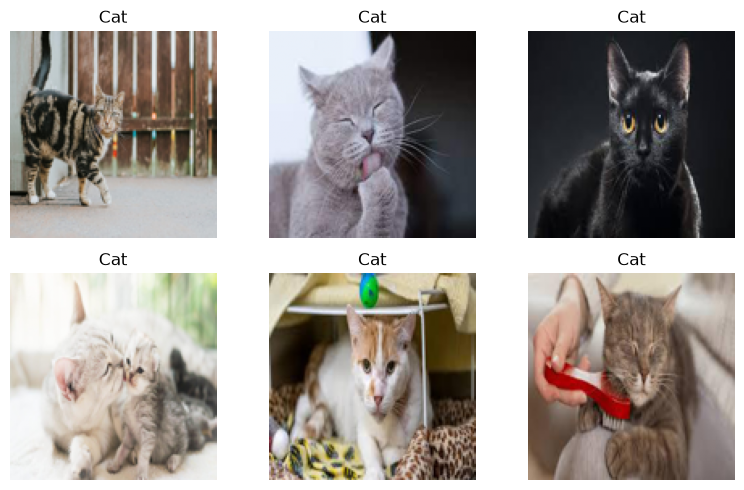

In [8]:
plt.figure(figsize=(8, 5))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    
    plt.imshow(images[i])
    
    if labels[i] == 0:
        plt.title("Cat")
    else:
        plt.title("Dog")
    
    plt.axis("off")

plt.tight_layout()
plt.show()

# Train and Validate the model

In [10]:
import numpy as np

# Shuffle the data
indices = np.arange(len(images))
np.random.shuffle(indices)

images = images[indices]
labels = labels[indices]

# 80% training, 20% testing
split = int(0.8 * len(images))

X_train = images[:split]
X_test = images[split:]

y_train = labels[:split]
y_test = labels[split:]

print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))
print("Training Labels:", len(y_train))
print("Testing Labels:", len(y_test))

Training Images: 234
Testing Images: 59
Training Labels: 234
Testing Labels: 59


In [11]:
# Simple Training

print("Training started...")

# Calculate average image for each class
cat_images = X_train[y_train == 0]
dog_images = X_train[y_train == 1]

cat_mean = np.mean(cat_images, axis=0)
dog_mean = np.mean(dog_images, axis=0)

print("Cat training images:", len(cat_images))
print("Dog training images:", len(dog_images))
print("Training completed!")

Training started...
Cat training images: 179
Dog training images: 55
Training completed!


# Model Accuracy

In [12]:
# Calculate Accuracy

correct = 0

for i in range(len(X_test)):
    image = X_test[i]

    cat_error = np.mean((image - cat_mean) ** 2)
    dog_error = np.mean((image - dog_mean) ** 2)

    if cat_error < dog_error:
        prediction = 0
    else:
        prediction = 1

    if prediction == y_test[i]:
        correct += 1

accuracy = (correct / len(X_test)) * 100

print("Model Accuracy:", round(accuracy, 2), "%")

Model Accuracy: 57.63 %


# Final Prediction

In [15]:
import os
from PIL import Image
import numpy as np

# Automatically find an image
image_file = None

for folder in ["dataset/test/cats", "dataset/test/dogs"]:
    if os.path.exists(folder):
        for file in os.listdir(folder):
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                image_file = os.path.join(folder, file)
                break
    if image_file:
        break

# Load image
img = Image.open(image_file).convert("RGB")
img = img.resize((128, 128))

test_image = np.array(img) / 255.0

# Calculate errors
cat_error = np.mean((test_image - cat_mean) ** 2)
dog_error = np.mean((test_image - dog_mean) ** 2)

# Final Prediction
if cat_error < dog_error:
    prediction = "Cat"
else:
    prediction = "Dog"

print("================================")
print("       FINAL PET PREDICTION")
print("================================")
print("Image:", os.path.basename(image_file))
print("Prediction:", prediction)
print("================================")

       FINAL PET PREDICTION
Image: cat_1.jpg
Prediction: Cat
